# Robustness Report Card for a CIFAR-10 Image Classifier

## 1. Project Overview and Objectives

This notebook builds, trains, and evaluates two lightweight convolutional neural networks on the **CIFAR-10** image classification benchmark—one trained with standard empirical risk minimization and one trained with **PGD adversarial training**.

**Key Objectives:**
- Implement and verify $L_\infty$ **FGSM** and **PGD** adversarial attacks in pixel space `[0, 1]`.
- Quantify clean accuracy, adversarial accuracy, **Attack Success Rate (ASR)**, and softmax prediction confidence across five perturbation budgets ($\epsilon \in \{0, 1/255, 2/255, 4/255, 8/255\}$).
- Compare penultimate-layer feature geometry and produce a consolidated **Robustness Report Card** entirely on CPU.

## 2. Environment Setup and Dependencies

Resolve the project root directory so this notebook works seamlessly whether launched from the repository root or from `notebooks/`, and verify library versions and CPU execution.

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torchvision

print(f"Project Root : {PROJECT_ROOT}")
print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__} (CUDA available: {torch.cuda.is_available()})")
print(f"Torchvision  : {torchvision.__version__}")
print(f"NumPy/Pandas : {np.__version__} / {pd.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")

Project Root : /home/rakesh/Desktop/Projects/cifar10-robustness-report-card
Python       : 3.14.4
PyTorch      : 2.15.0+cu132 (CUDA available: False)
Torchvision  : 0.29.2+cu132
NumPy/Pandas : 2.5.4 / 3.1.1
Scikit-learn : 1.9.1


## 3. Imports and Reproducibility

Import the modular project components from `config.py` and `src/` and lock random seeds across Python, NumPy, and PyTorch.

In [2]:
from IPython.display import Image, display

from config import CIFAR10_CLASSES, get_config, set_seed
from src.attacks import fgsm_attack, pgd_attack
from src.data import denormalize, get_cifar10_dataloaders
from src.evaluate import (
    collect_features,
    collect_predictions_and_confidences,
    evaluate_model_across_epsilons,
)
from src.model import CIFAR10CNN, count_trainable_parameters
from src.plots import (
    plot_accuracy_vs_epsilon,
    plot_adversarial_examples_grid,
    plot_confidence_histograms,
    plot_confusion_matrices,
    plot_training_curves,
    plot_tsne_features,
)
from src.train import train_model

## 4. Configuration and Hyperparameters

Select an experiment preset. Use `RUN_MODE = "sanity_check"` for a quick end-to-end smoke test (~1–2 minutes on CPU) or `RUN_MODE = "default"` for the full portfolio run.

In [3]:
RUN_MODE = "default"  # Switch to "sanity_check" for a quick CPU smoke test

cfg = get_config(mode=RUN_MODE, project_root=PROJECT_ROOT)
cfg.ensure_directories()
set_seed(cfg.seed)

print(cfg)

ExperimentConfig(project_root=PosixPath('/home/rakesh/Desktop/Projects/cifar10-robustness-report-card'), data_dir=PosixPath('/home/rakesh/Desktop/Projects/cifar10-robustness-report-card/data'), figures_dir=PosixPath('/home/rakesh/Desktop/Projects/cifar10-robustness-report-card/figures'), checkpoints_dir=PosixPath('/home/rakesh/Desktop/Projects/cifar10-robustness-report-card/checkpoints'), results_dir=PosixPath('/home/rakesh/Desktop/Projects/cifar10-robustness-report-card/results'), device='cpu', seed=42, num_workers=0, train_subset_size=10000, val_ratio=0.1, test_subset_size=2000, batch_size=128, optimizer='adam', learning_rate=0.001, weight_decay=0.0001, standard_epochs=12, adv_epochs=8, adv_train_epsilon=0.01568627450980392, adv_train_alpha=0.00784313725490196, adv_train_steps=3, adv_train_random_start=True, epsilons=[0.0, 0.00392156862745098, 0.00784313725490196, 0.01568627450980392, 0.03137254901960784], eval_pgd_steps=10, eval_pgd_random_start=True, eval_vis_epsilon=0.031372549019

## 5. CIFAR-10 Dataset Preparation

Download CIFAR-10 automatically if missing, apply consistent channel normalization, and build reproducible train, validation, and test `DataLoader`s.

In [4]:
train_loader, val_loader, test_loader = get_cifar10_dataloaders(
    data_dir=cfg.data_dir,
    batch_size=cfg.batch_size,
    train_subset_size=cfg.train_subset_size,
    test_subset_size=cfg.test_subset_size,
    val_ratio=cfg.val_ratio,
    seed=cfg.seed,
    num_workers=cfg.num_workers,
)

print(f"Train samples : {len(train_loader.dataset):,}")
print(f"Val samples   : {len(val_loader.dataset):,}")
print(f"Test samples  : {len(test_loader.dataset):,}")

sample_images, sample_labels = next(iter(test_loader))
print(f"Batch shape   : {tuple(sample_images.shape)}, Labels shape: {tuple(sample_labels.shape)}")

Train samples : 9,000
Val samples   : 1,000
Test samples  : 2,000
Batch shape   : (128, 3, 32, 32), Labels shape: (128,)


## 6. CNN Architecture

Instantiate the lightweight `CIFAR10CNN` (~305k trainable parameters) and verify both logit output shapes and penultimate-layer feature shapes for t-SNE analysis.

In [5]:
standard_model = CIFAR10CNN()
param_count = count_trainable_parameters(standard_model, verbose=True)

with torch.no_grad():
    test_logits = standard_model(sample_images[:4])
    test_feats = standard_model.extract_features(sample_images[:4])

print(f"Logits shape  : {tuple(test_logits.shape)}")
print(f"Feature shape : {tuple(test_feats.shape)}")

CIFAR10CNN trainable parameters: 304,794
Logits shape  : (4, 10)
Feature shape : (4, 80)


## 7. FGSM and PGD Attack Implementations

Verify that both `fgsm_attack` and `pgd_attack` strictly enforce $L_\infty$ perturbation bounds in `[0, 1]` pixel space, keep outputs within valid pixel limits, and never mutate original input tensors.

In [6]:
check_eps = 8 / 255
x_check = sample_images[:8].clone()
y_check = sample_labels[:8].clone()
x_orig_px = denormalize(x_check).clamp(0.0, 1.0)

fgsm_out = fgsm_attack(standard_model, x_check, y_check, epsilon=check_eps)
pgd_out = pgd_attack(standard_model, x_check, y_check, epsilon=check_eps, alpha=2/255, num_steps=5)

for name, adv in [("FGSM", fgsm_out), ("PGD", pgd_out)]:
    adv_px = denormalize(adv)
    linf = (adv_px - x_orig_px).abs().max().item()
    print(
        f"{name:4s} | max |delta| = {linf:.6f} (limit {check_eps:.6f}) | "
        f"pixel range = [{adv_px.min().item():.4f}, {adv_px.max().item():.4f}]"
    )
    assert linf <= check_eps + 1e-5
    assert adv_px.min().item() >= -1e-5 and adv_px.max().item() <= 1.0 + 1e-5

print("Attack constraint verification passed.")

FGSM | max |delta| = 0.031373 (limit 0.031373) | pixel range = [0.0000, 1.0000]
PGD  | max |delta| = 0.031373 (limit 0.031373) | pixel range = [0.0000, 1.0000]
Attack constraint verification passed.


## 8. Standard Model Training

Train the baseline `CIFAR10CNN` on clean training images using cross-entropy loss and save the best checkpoint and training history.

In [7]:
standard_history = train_model(
    model=standard_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=cfg.standard_epochs,
    learning_rate=cfg.learning_rate,
    weight_decay=cfg.weight_decay,
    optimizer_name=cfg.optimizer,
    adversarial_training=False,
    device=cfg.device,
    seed=cfg.seed,
    checkpoint_path=cfg.checkpoints_dir / "standard_cnn.pt",
    history_path=cfg.results_dir / "standard_history.json",
)

[Standard] Epoch 01/12 | Train Loss: 1.9417, Train Acc: 0.2730 | Val Loss: 1.6149, Val Acc: 0.3910 | 13.8s
[Standard] Epoch 02/12 | Train Loss: 1.6410, Train Acc: 0.3832 | Val Loss: 1.4534, Val Acc: 0.4940 | 12.2s
[Standard] Epoch 03/12 | Train Loss: 1.4824, Train Acc: 0.4510 | Val Loss: 1.3684, Val Acc: 0.5000 | 12.2s
[Standard] Epoch 04/12 | Train Loss: 1.3818, Train Acc: 0.4941 | Val Loss: 1.2052, Val Acc: 0.5530 | 16.0s
[Standard] Epoch 05/12 | Train Loss: 1.2813, Train Acc: 0.5242 | Val Loss: 1.1250, Val Acc: 0.5930 | 13.9s
[Standard] Epoch 06/12 | Train Loss: 1.2088, Train Acc: 0.5631 | Val Loss: 1.1449, Val Acc: 0.5930 | 12.8s
[Standard] Epoch 07/12 | Train Loss: 1.1480, Train Acc: 0.5854 | Val Loss: 1.0602, Val Acc: 0.6410 | 12.9s
[Standard] Epoch 08/12 | Train Loss: 1.0827, Train Acc: 0.6112 | Val Loss: 1.0027, Val Acc: 0.6540 | 13.6s
[Standard] Epoch 09/12 | Train Loss: 1.0460, Train Acc: 0.6246 | Val Loss: 0.9275, Val Acc: 0.6770 | 12.8s
[Standard] Epoch 10/12 | Train Loss: 

## 9. Adversarial Model Training

Train a fresh copy of `CIFAR10CNN` using PGD adversarial examples generated on the fly during each training batch.

In [8]:
adversarial_model = CIFAR10CNN()

adversarial_history = train_model(
    model=adversarial_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=cfg.adv_epochs,
    learning_rate=cfg.learning_rate,
    weight_decay=cfg.weight_decay,
    optimizer_name=cfg.optimizer,
    adversarial_training=True,
    pgd_epsilon=cfg.adv_train_epsilon,
    pgd_alpha=cfg.adv_train_alpha,
    pgd_steps=cfg.adv_train_steps,
    pgd_random_start=cfg.adv_train_random_start,
    device=cfg.device,
    seed=cfg.seed,
    checkpoint_path=cfg.checkpoints_dir / "adversarial_cnn.pt",
    history_path=cfg.results_dir / "adversarial_history.json",
)

[Adversarial (PGD)] Epoch 01/08 | Train Loss: 2.1105, Train Acc: 0.1982 | Val Loss: 1.8205, Val Acc: 0.3320 | 42.3s
[Adversarial (PGD)] Epoch 02/08 | Train Loss: 1.9774, Train Acc: 0.2549 | Val Loss: 1.6913, Val Acc: 0.3610 | 36.3s
[Adversarial (PGD)] Epoch 03/08 | Train Loss: 1.9223, Train Acc: 0.2732 | Val Loss: 1.5916, Val Acc: 0.4210 | 38.4s
[Adversarial (PGD)] Epoch 04/08 | Train Loss: 1.8678, Train Acc: 0.2952 | Val Loss: 1.5554, Val Acc: 0.4380 | 38.7s
[Adversarial (PGD)] Epoch 05/08 | Train Loss: 1.8407, Train Acc: 0.3127 | Val Loss: 1.5020, Val Acc: 0.4710 | 45.3s
[Adversarial (PGD)] Epoch 06/08 | Train Loss: 1.8074, Train Acc: 0.3241 | Val Loss: 1.4699, Val Acc: 0.4680 | 44.3s
[Adversarial (PGD)] Epoch 07/08 | Train Loss: 1.7880, Train Acc: 0.3249 | Val Loss: 1.4623, Val Acc: 0.4730 | 44.4s
[Adversarial (PGD)] Epoch 08/08 | Train Loss: 1.7750, Train Acc: 0.3360 | Val Loss: 1.4428, Val Acc: 0.4830 | 40.8s


## 10. Model Evaluation Across Epsilon Values

Evaluate both models on identical test batches across all epsilon values under both **PGD** and **FGSM**.

In [9]:
std_results = evaluate_model_across_epsilons(
    model=standard_model,
    model_name="Standard",
    test_loader=test_loader,
    epsilons=cfg.epsilons,
    attack_types=("pgd", "fgsm"),
    pgd_steps=cfg.eval_pgd_steps,
    pgd_random_start=cfg.eval_pgd_random_start,
    device=cfg.device,
)

adv_results = evaluate_model_across_epsilons(
    model=adversarial_model,
    model_name="Adversarial",
    test_loader=test_loader,
    epsilons=cfg.epsilons,
    attack_types=("pgd", "fgsm"),
    pgd_steps=cfg.eval_pgd_steps,
    pgd_random_start=cfg.eval_pgd_random_start,
    device=cfg.device,
)

results_df = pd.concat([std_results, adv_results], ignore_index=True)
results_df.to_csv(cfg.results_dir / "evaluation_metrics.csv", index=False)

[Standard | PGD | eps=0/255] Clean Acc: 0.6870 | Adv Acc: 0.6870 | ASR: 0.0000 | Conf (Clean/Adv): 0.663/0.663
[Standard | PGD | eps=1/255] Clean Acc: 0.6870 | Adv Acc: 0.4090 | ASR: 0.4047 | Conf (Clean/Adv): 0.663/0.626
[Standard | PGD | eps=2/255] Clean Acc: 0.6870 | Adv Acc: 0.1985 | ASR: 0.7111 | Conf (Clean/Adv): 0.663/0.648
[Standard | PGD | eps=4/255] Clean Acc: 0.6870 | Adv Acc: 0.0225 | ASR: 0.9672 | Conf (Clean/Adv): 0.663/0.763
[Standard | PGD | eps=8/255] Clean Acc: 0.6870 | Adv Acc: 0.0000 | ASR: 1.0000 | Conf (Clean/Adv): 0.663/0.893
[Standard | FGSM | eps=0/255] Clean Acc: 0.6870 | Adv Acc: 0.6870 | ASR: 0.0000 | Conf (Clean/Adv): 0.663/0.663
[Standard | FGSM | eps=1/255] Clean Acc: 0.6870 | Adv Acc: 0.4360 | ASR: 0.3654 | Conf (Clean/Adv): 0.663/0.621
[Standard | FGSM | eps=2/255] Clean Acc: 0.6870 | Adv Acc: 0.2855 | ASR: 0.5844 | Conf (Clean/Adv): 0.663/0.615
[Standard | FGSM | eps=4/255] Clean Acc: 0.6870 | Adv Acc: 0.1035 | ASR: 0.8493 | Conf (Clean/Adv): 0.663/0.6

## 11. Robustness Metrics and Comparisons

Inspect the structured PGD evaluation table comparing clean accuracy, adversarial accuracy, Attack Success Rate (ASR), and mean softmax confidence.

In [10]:
pgd_table = results_df[results_df["attack"] == "PGD"][
    [
        "model",
        "epsilon_255",
        "clean_accuracy",
        "adversarial_accuracy",
        "attack_success_rate",
        "mean_clean_confidence",
        "mean_adversarial_confidence",
    ]
].reset_index(drop=True)

display(pgd_table.style.format({
    "clean_accuracy": "{:.4f}",
    "adversarial_accuracy": "{:.4f}",
    "attack_success_rate": "{:.4f}",
    "mean_clean_confidence": "{:.4f}",
    "mean_adversarial_confidence": "{:.4f}",
}))

,model,epsilon_255,clean_accuracy,adversarial_accuracy,attack_success_rate,mean_clean_confidence,mean_adversarial_confidence
0,Standard,0/255,0.6870,0.6870,0.0000,0.6631,0.6631
1,Standard,1/255,0.6870,0.4090,0.4047,0.6631,0.6257
2,Standard,2/255,0.6870,0.1985,0.7111,0.6631,0.6477
3,Standard,4/255,0.6870,0.0225,0.9672,0.6631,0.7635
4,Standard,8/255,0.6870,0.0000,1.0000,0.6631,0.8933
5,Adversarial,0/255,0.5020,0.5020,0.0000,0.3546,0.3546
6,Adversarial,1/255,0.5020,0.4675,0.0707,0.3546,0.3493
7,Adversarial,2/255,0.5020,0.4365,0.1335,0.3546,0.3448
8,Adversarial,4/255,0.5020,0.3620,0.2829,0.3546,0.3379
9,Adversarial,8/255,0.5020,0.2395,0.5249,0.3546,0.3337


## 12. Visualization and Robustness Report Card

Generate and save all six 300 DPI PNG visualizations inside `figures/` and display them inline.

Saved: figures/training_curves.png


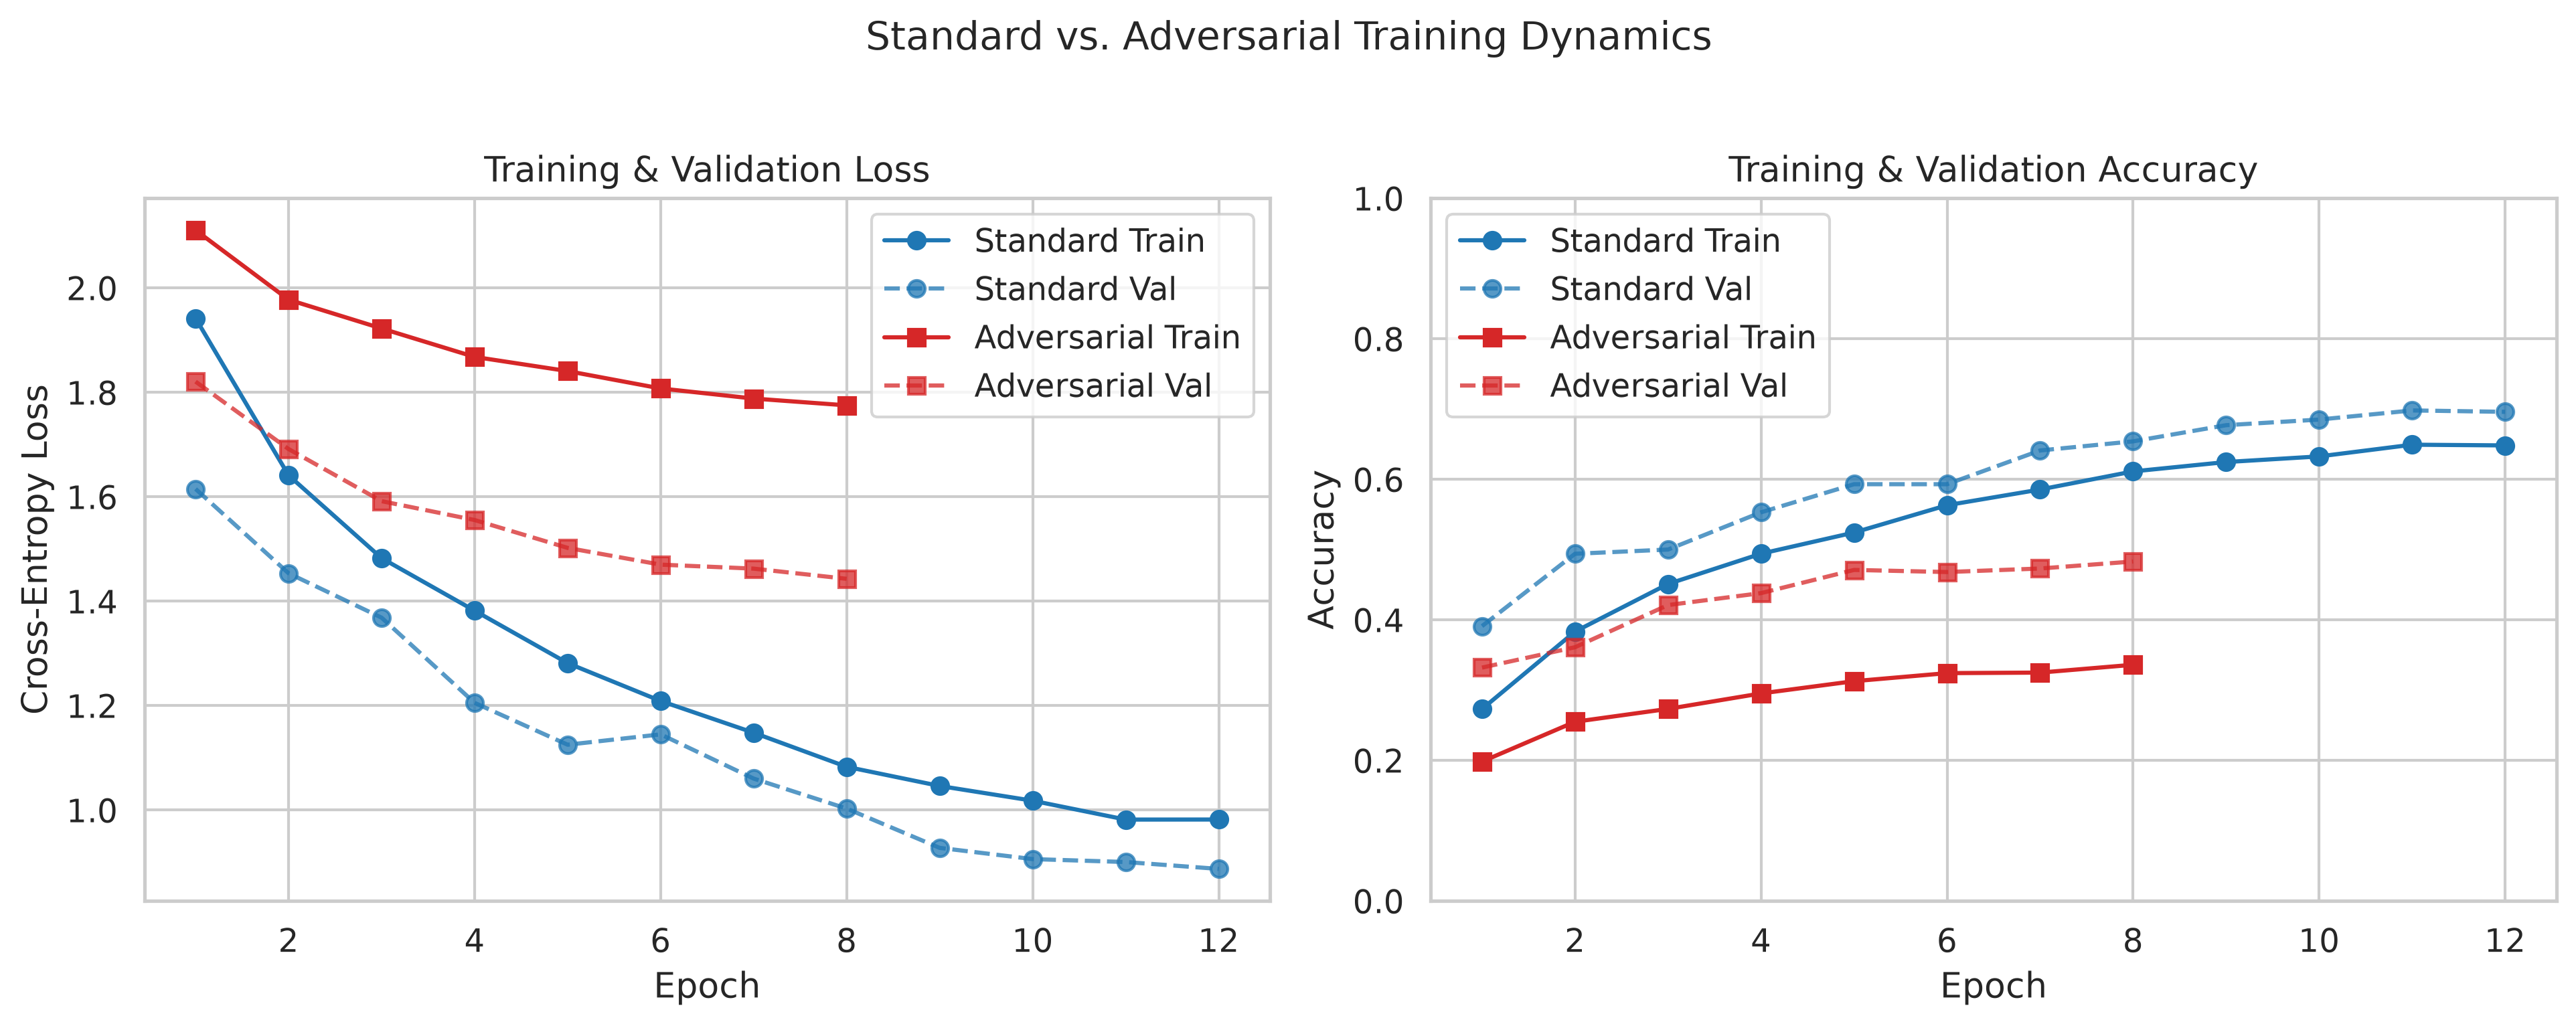

Saved: figures/accuracy_vs_epsilon.png


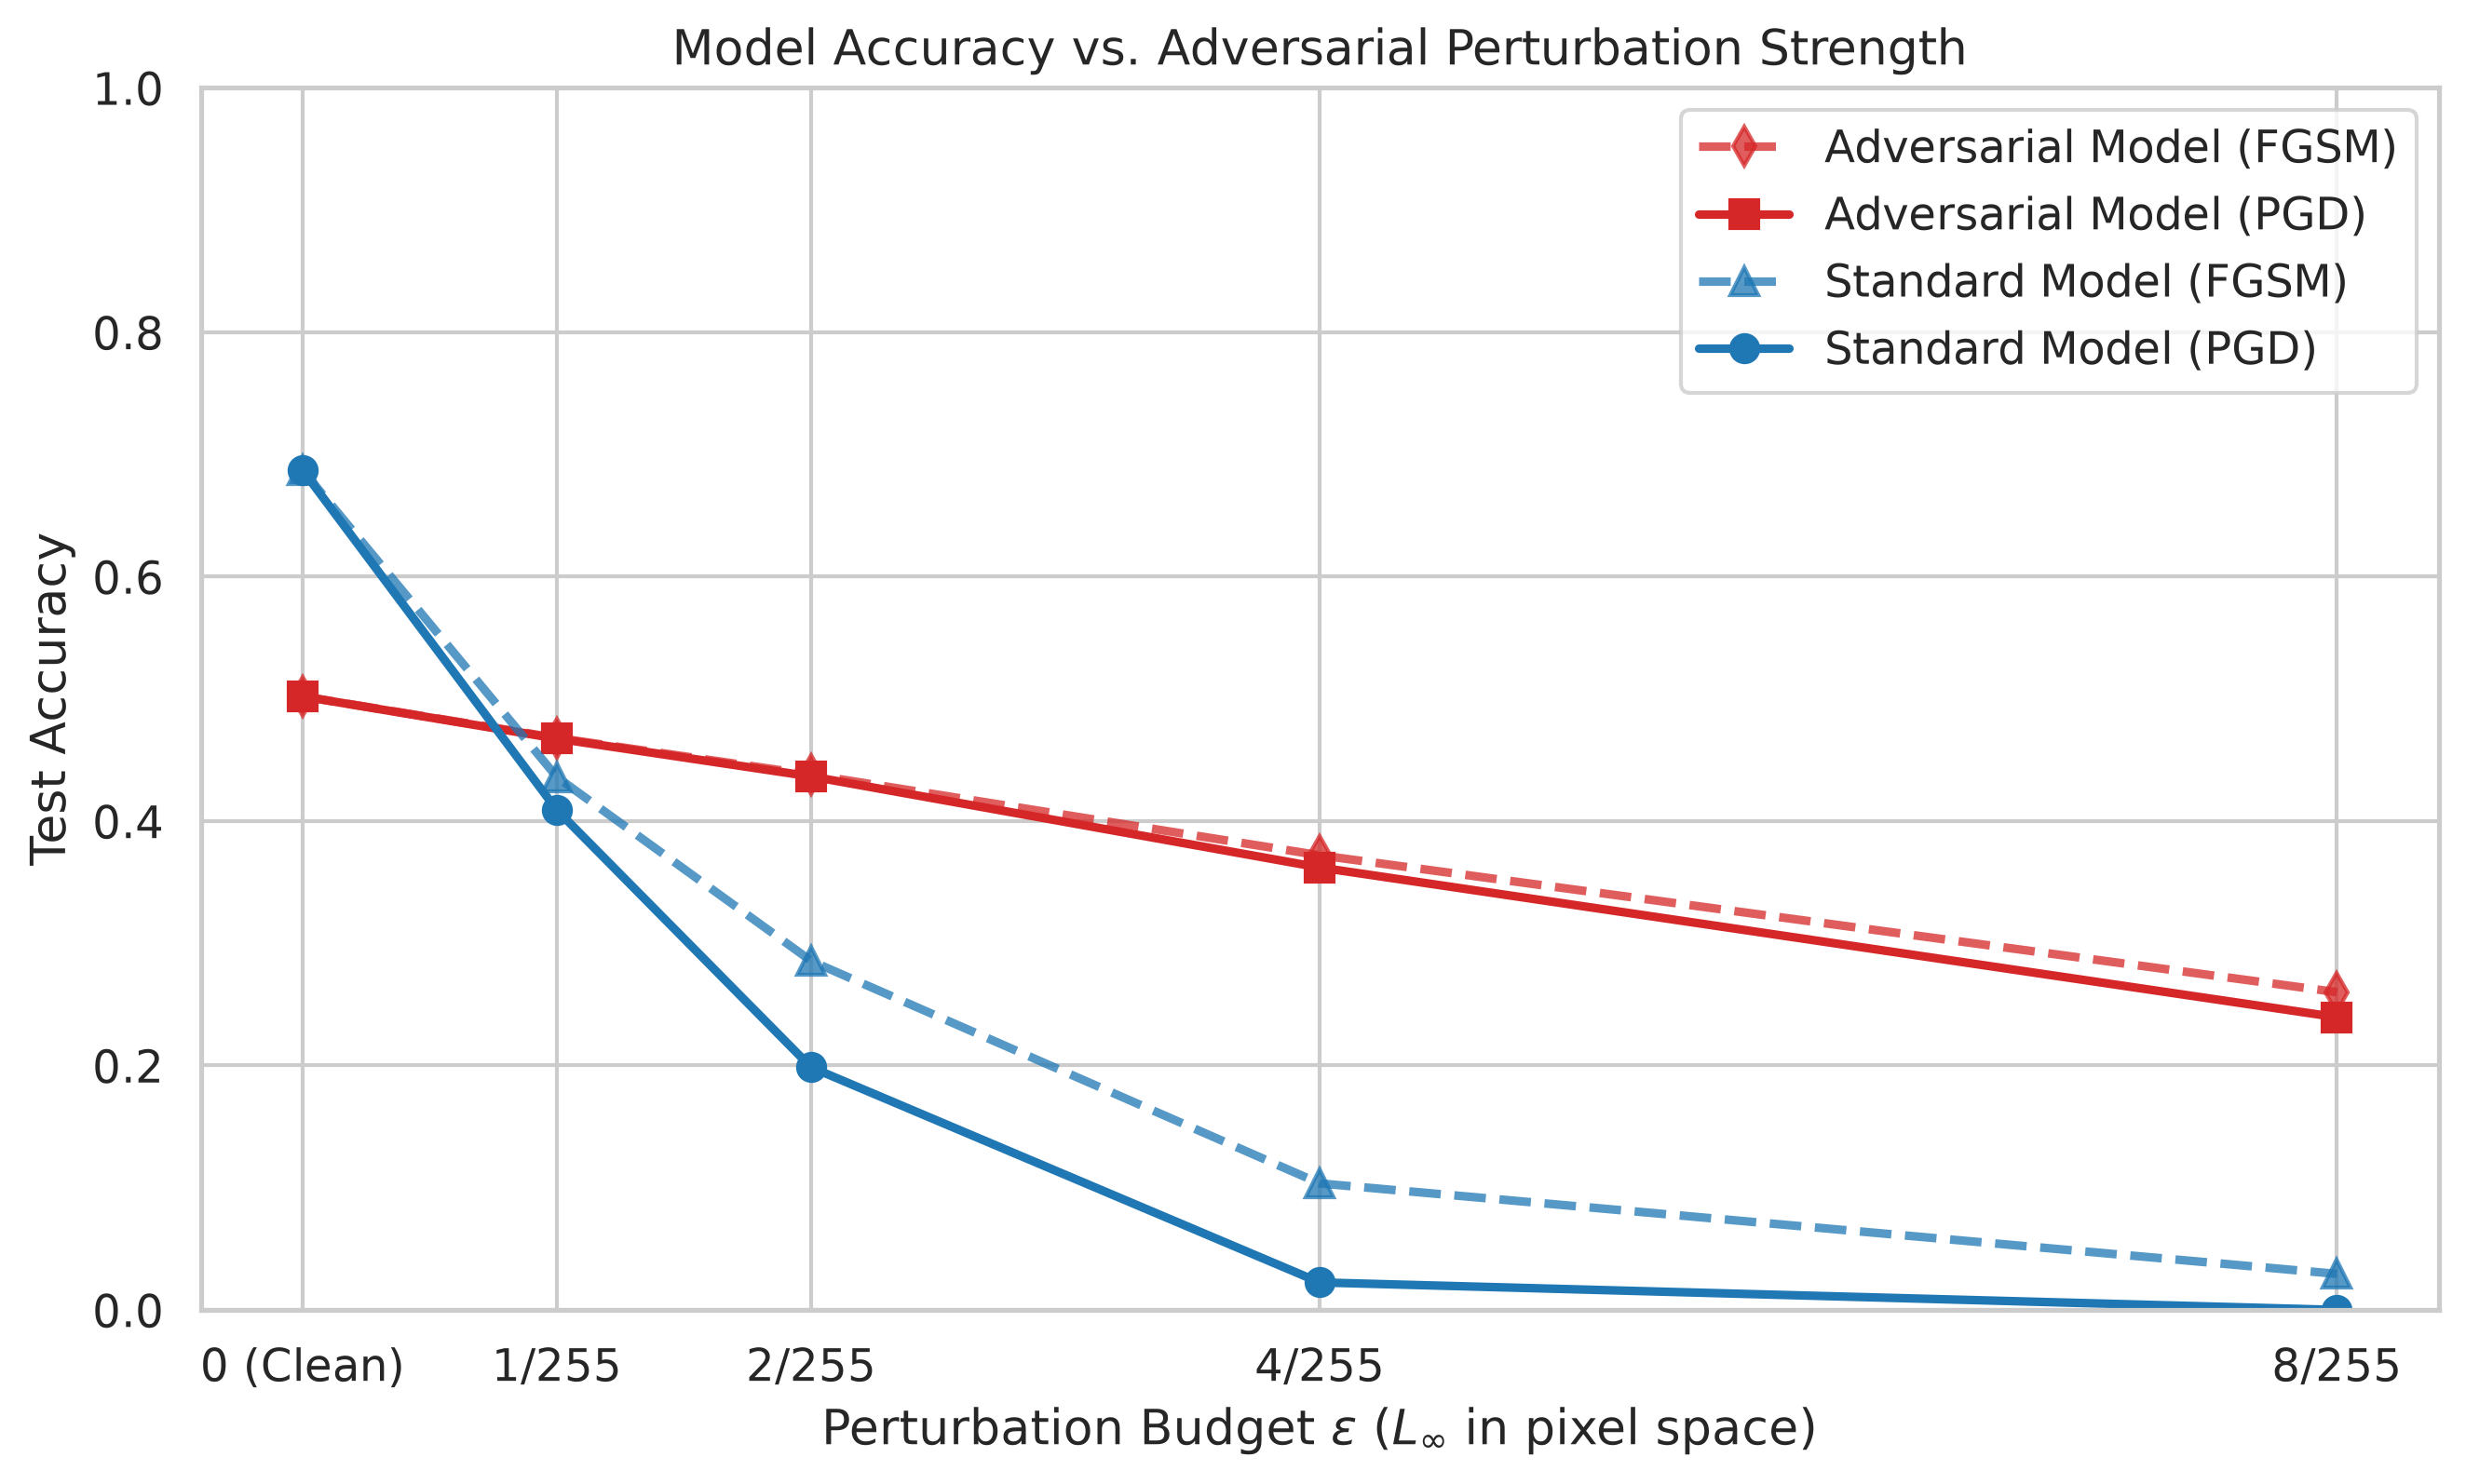

Saved: figures/adversarial_examples_grid.png


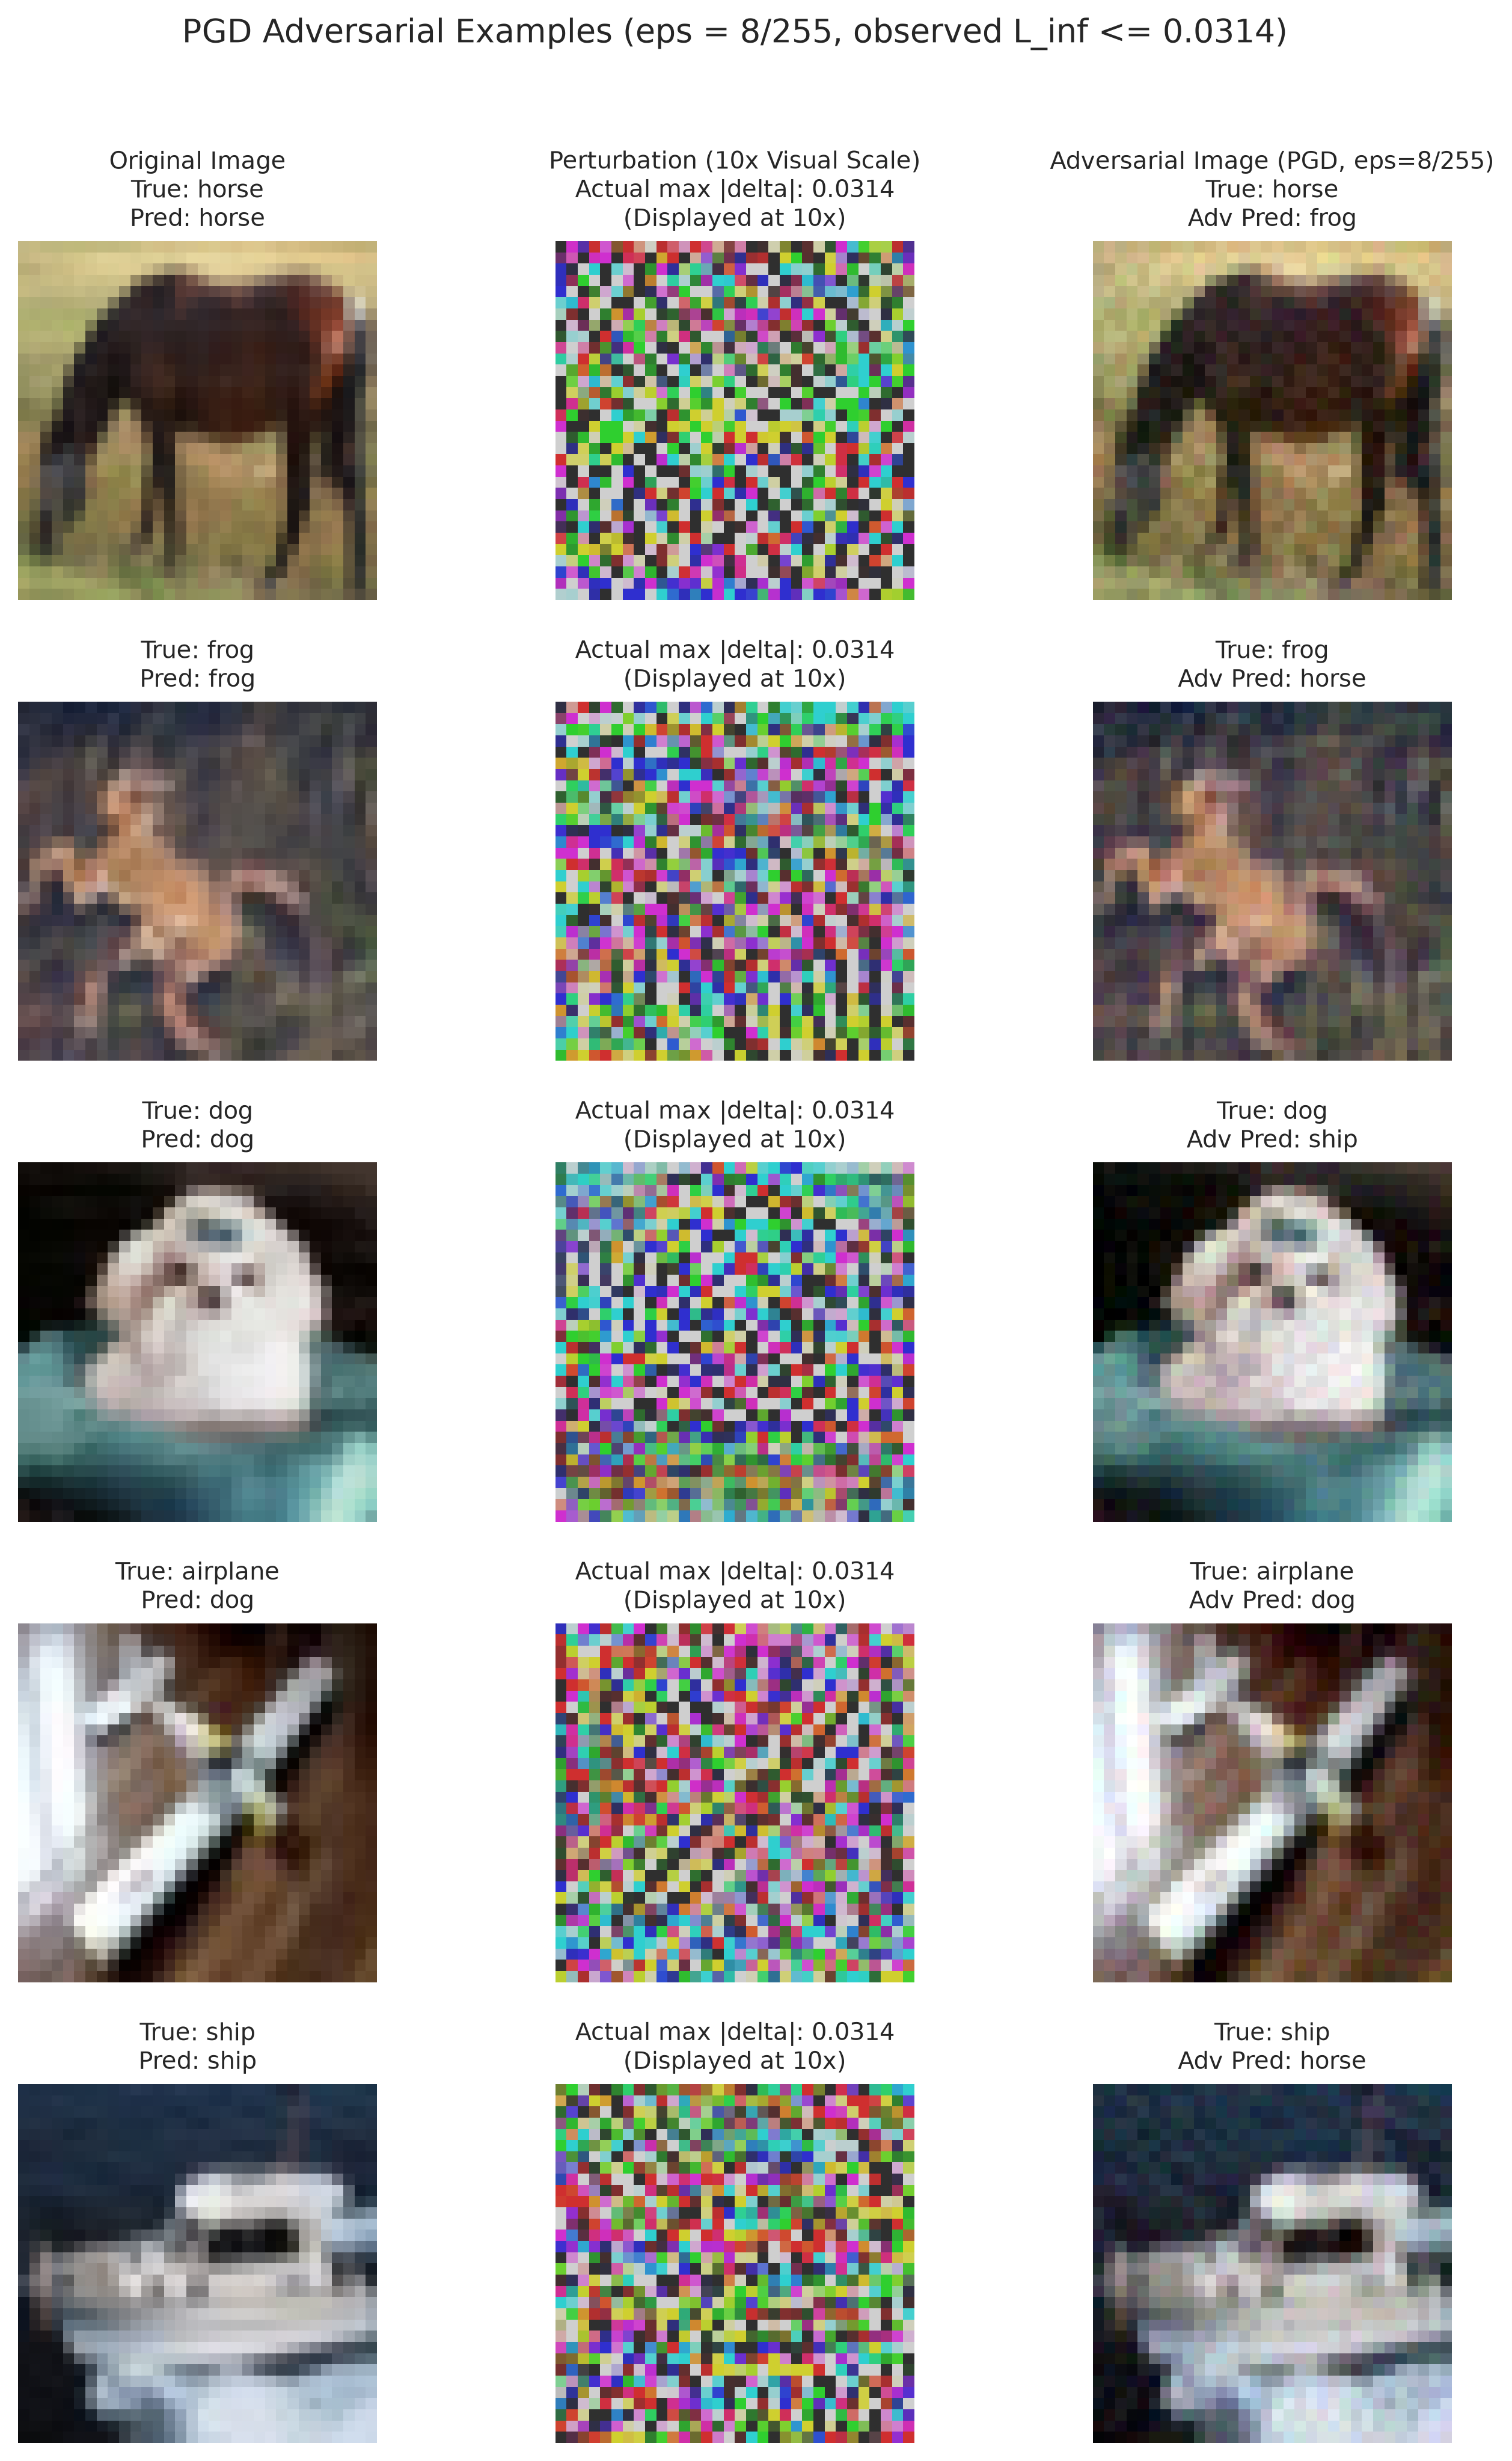

Saved: figures/confusion_matrices.png


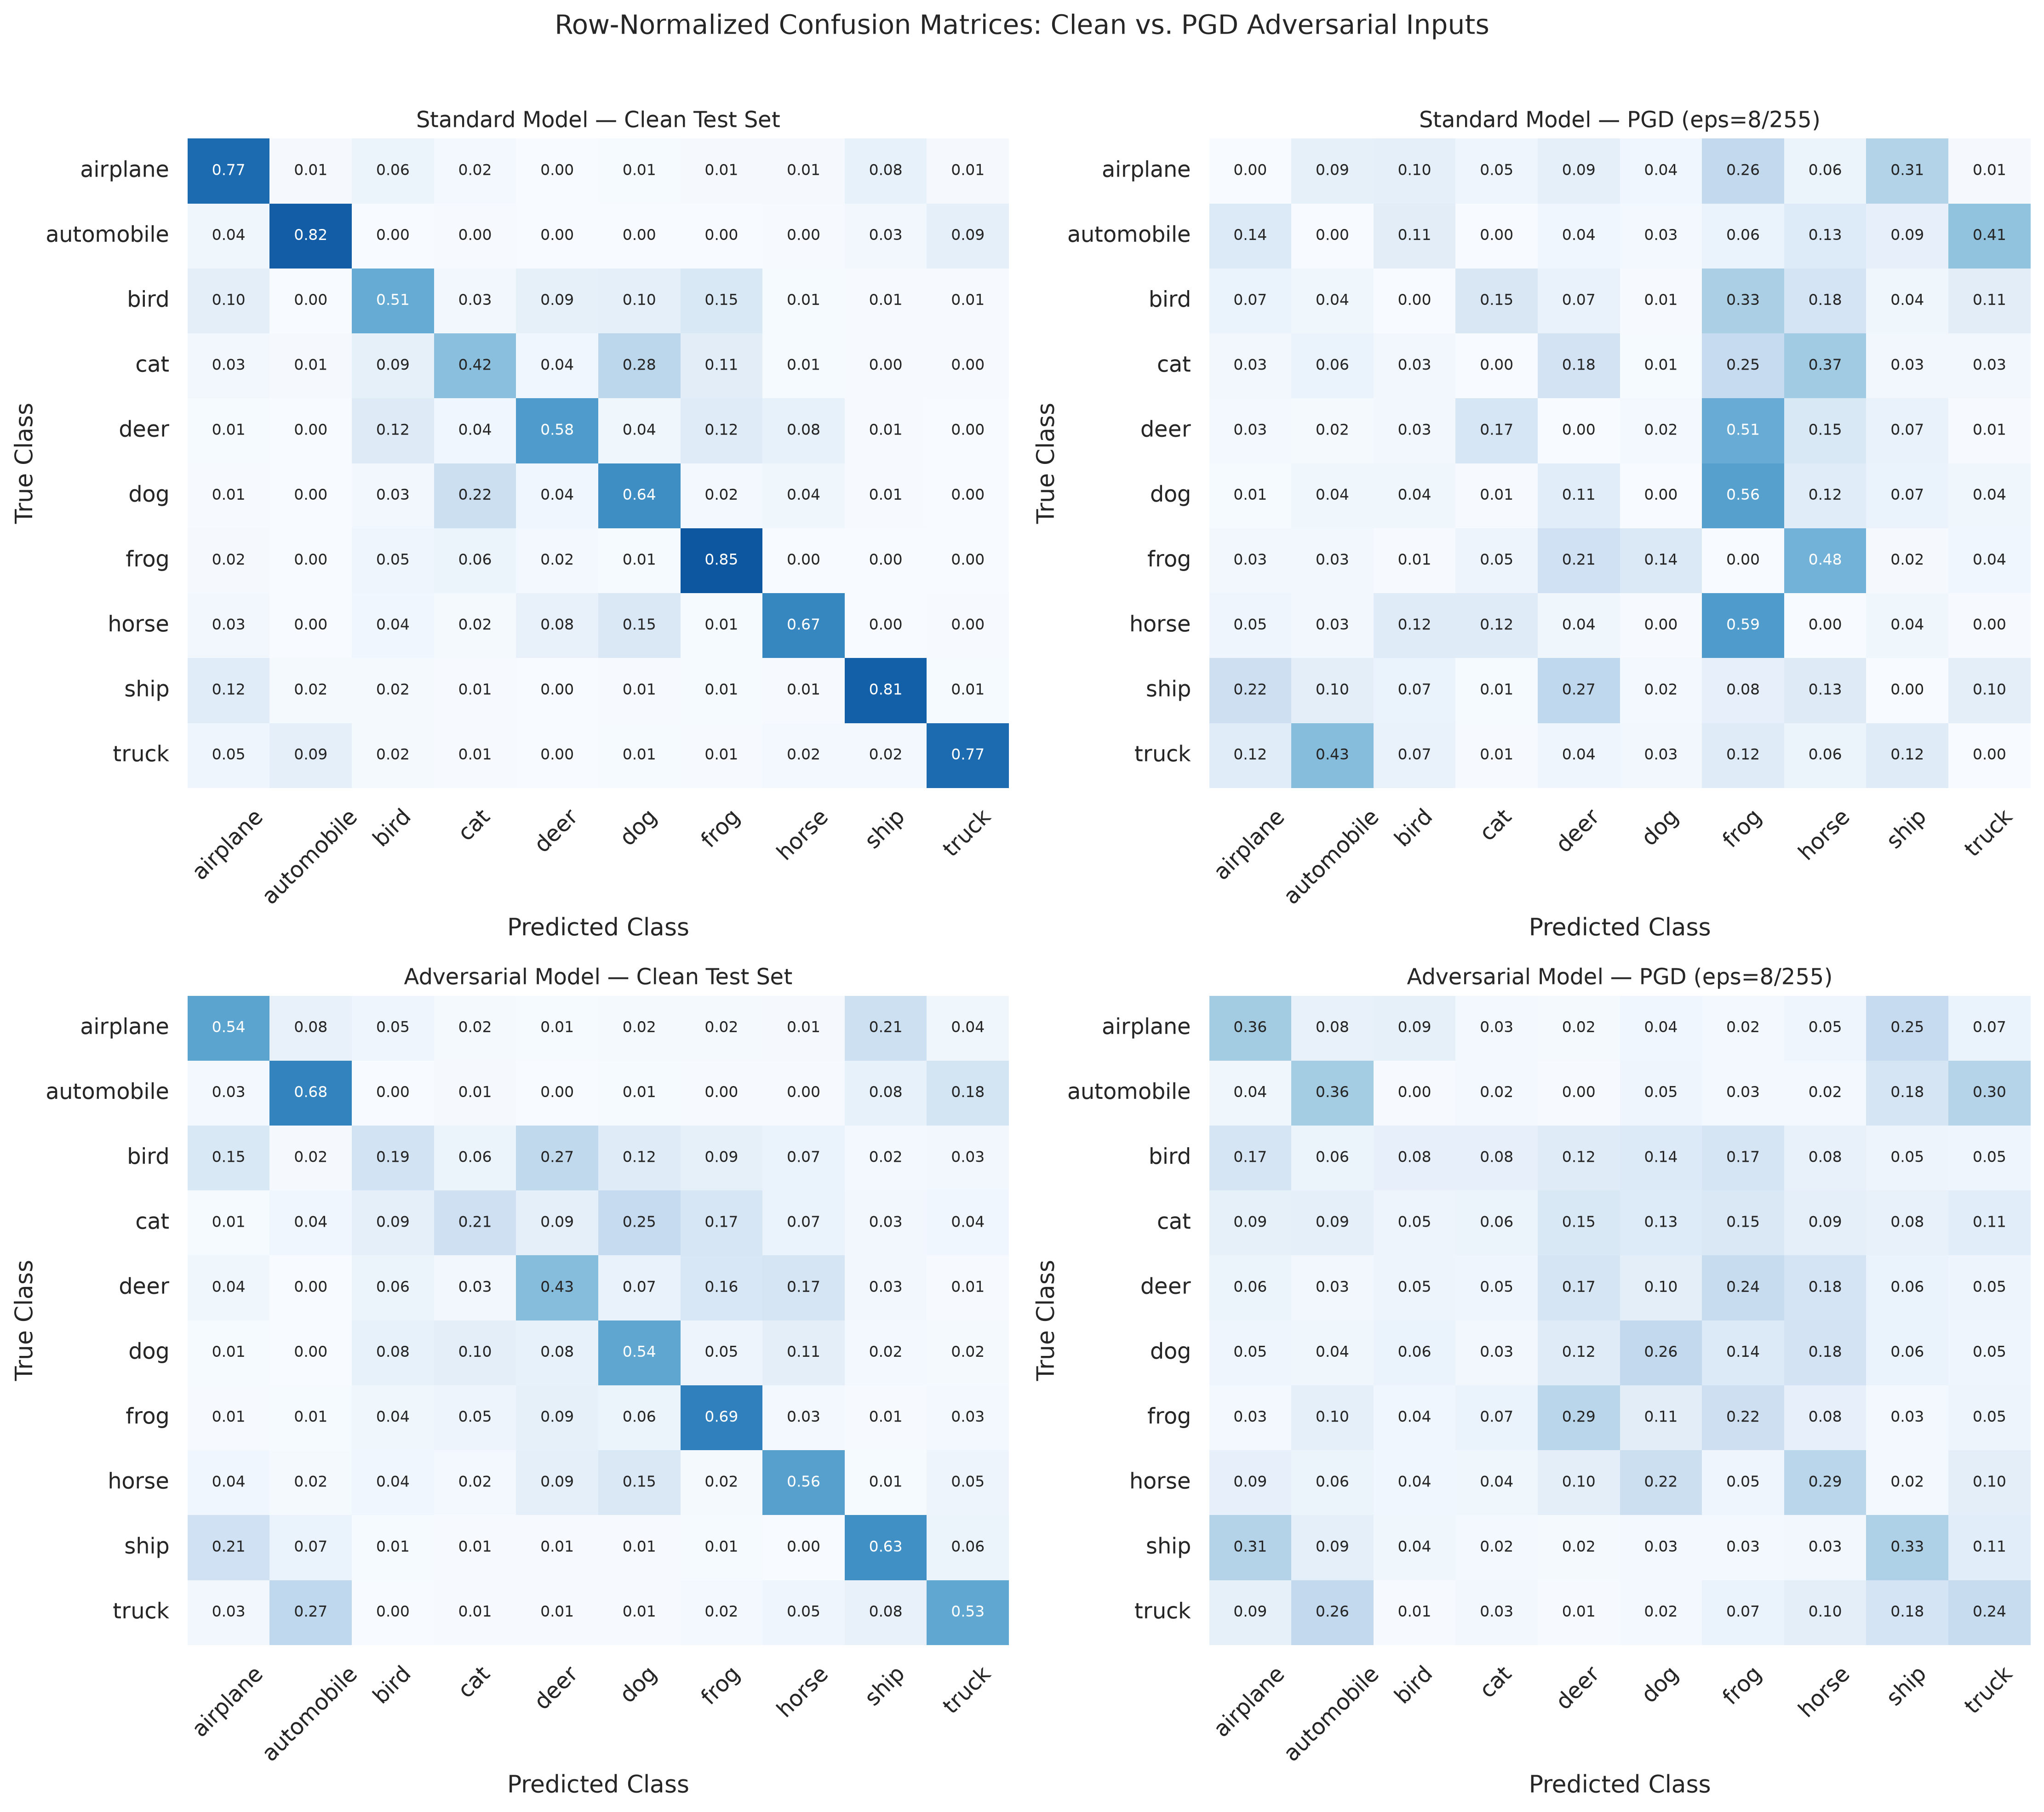

Saved: figures/confidence_histograms.png


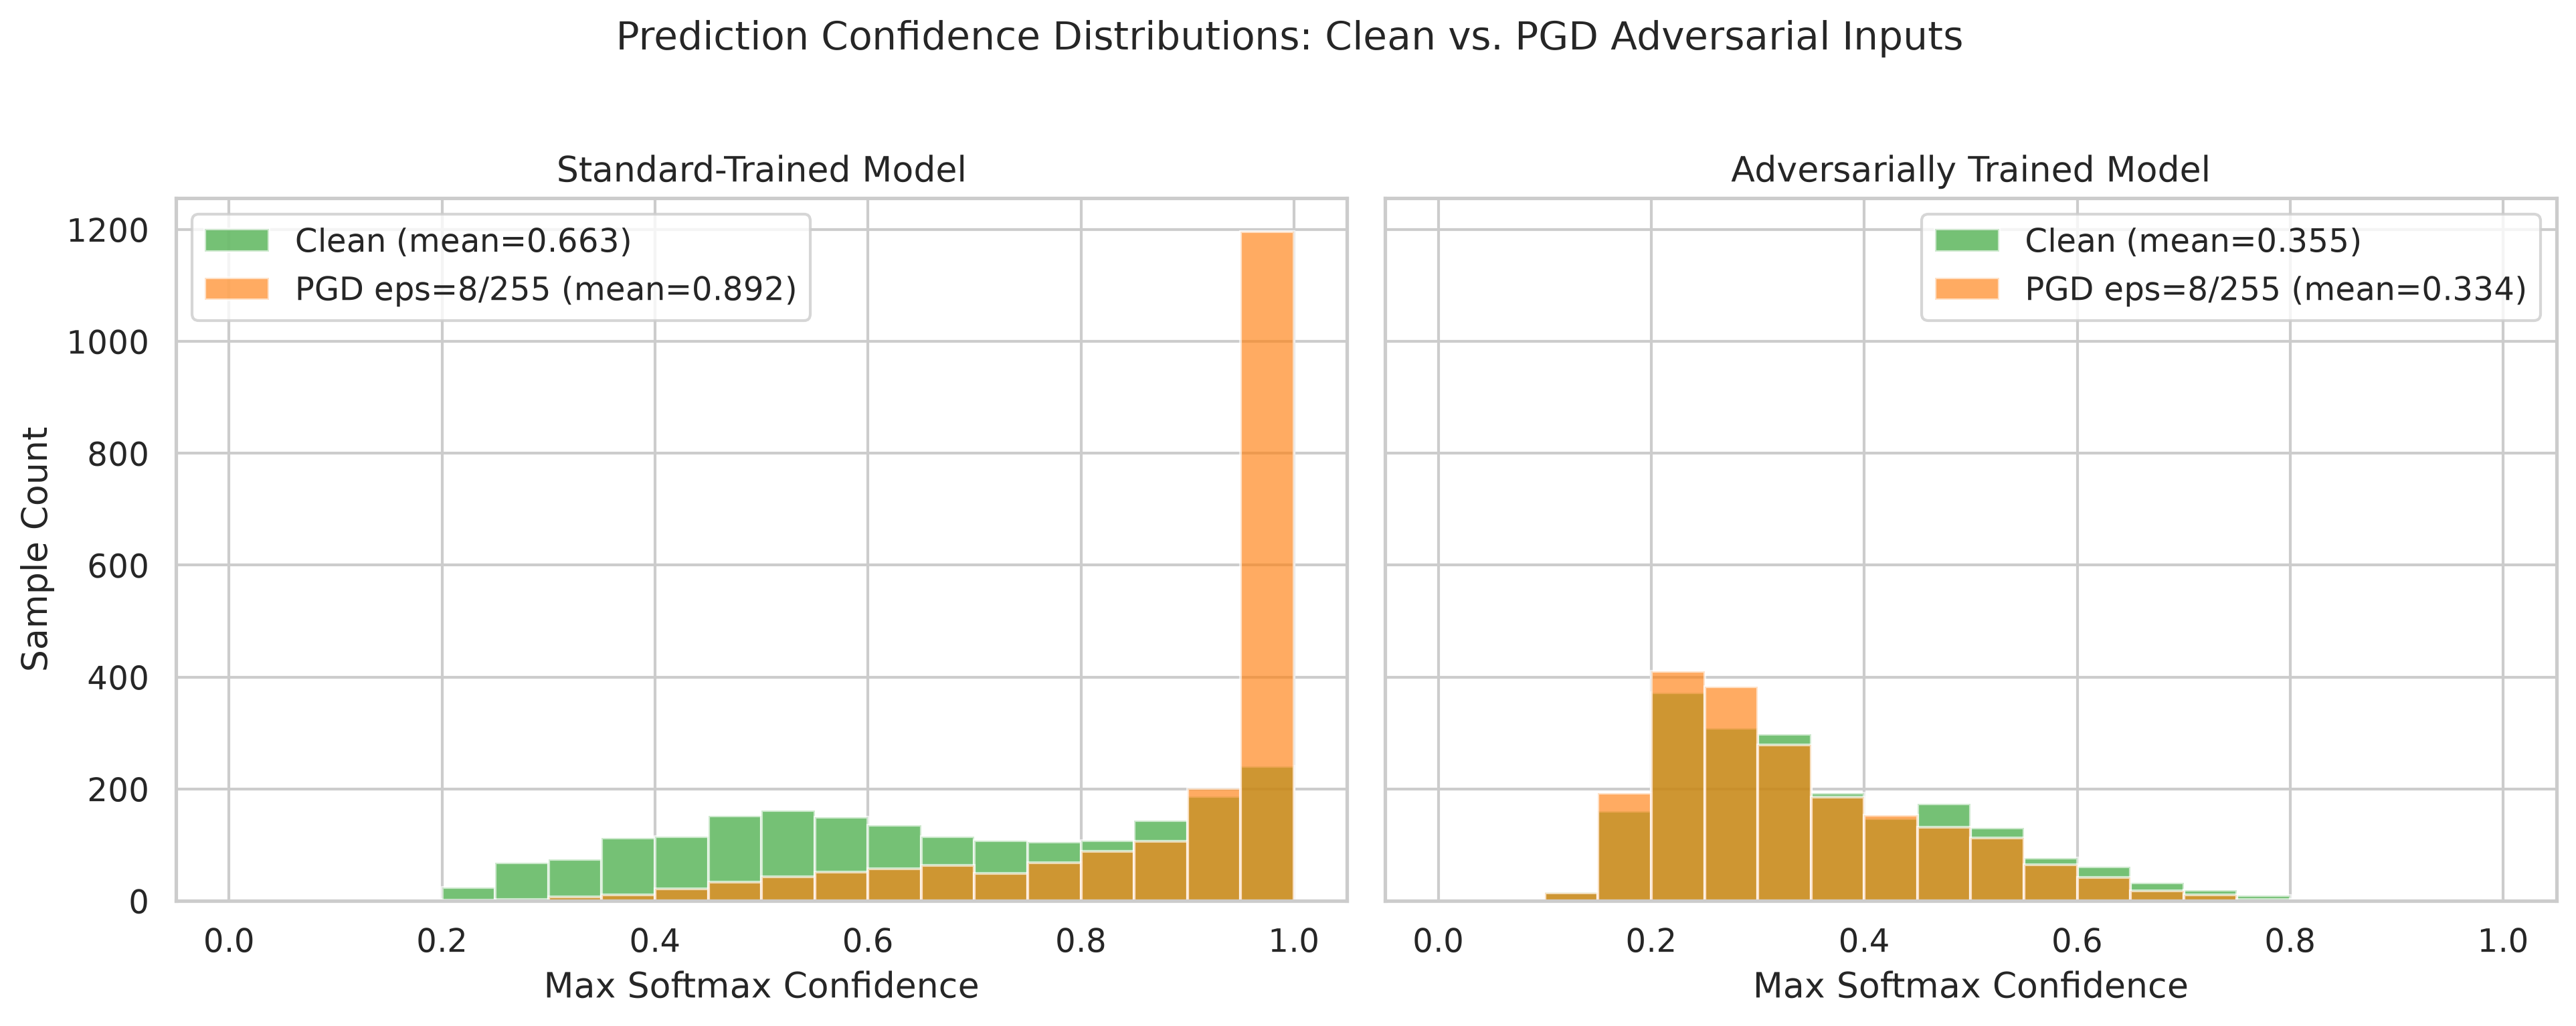

Saved: figures/tsne_features.png


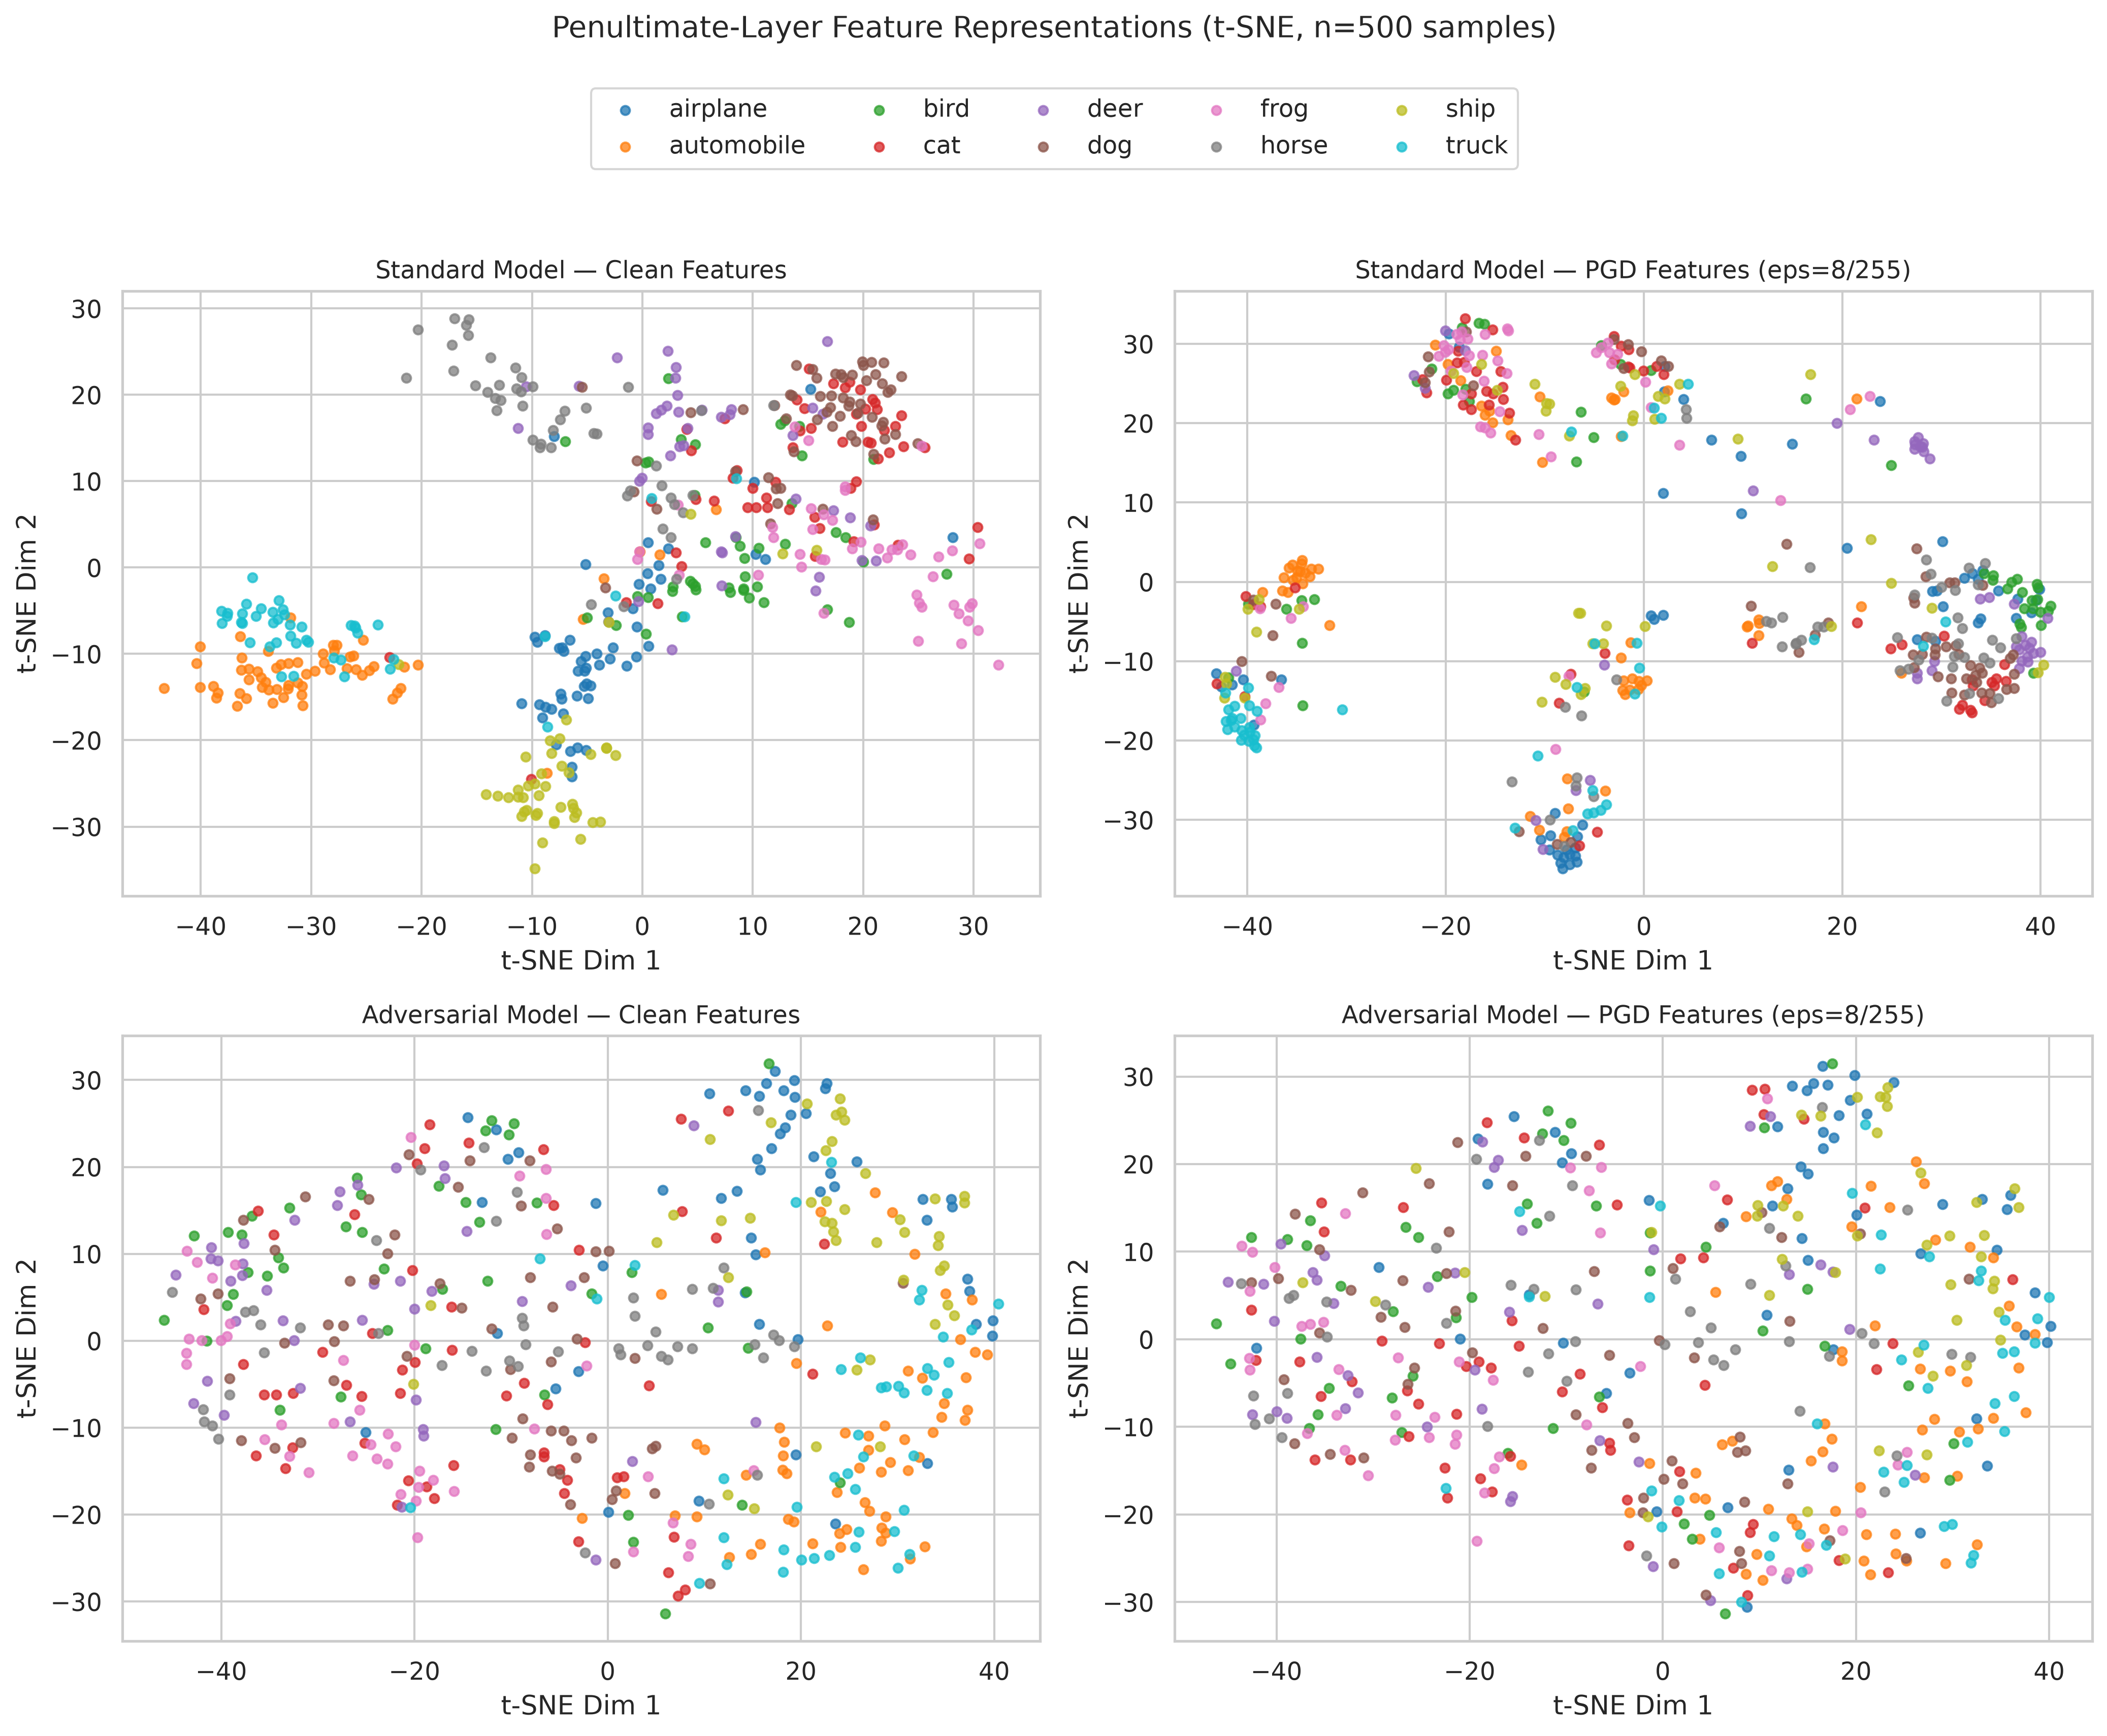

In [11]:
vis_eps = cfg.eval_vis_epsilon

fig1 = plot_training_curves(
    standard_history, adversarial_history, cfg.figures_dir / "training_curves.png", dpi=cfg.figure_dpi
)
fig2 = plot_accuracy_vs_epsilon(
    results_df, cfg.figures_dir / "accuracy_vs_epsilon.png", dpi=cfg.figure_dpi
)
fig3 = plot_adversarial_examples_grid(
    model=standard_model,
    images=sample_images,
    labels=sample_labels,
    epsilon=vis_eps,
    pgd_steps=cfg.eval_pgd_steps,
    save_path=cfg.figures_dir / "adversarial_examples_grid.png",
    device=cfg.device,
    dpi=cfg.figure_dpi,
)

y_true, std_clean_preds, std_clean_conf = collect_predictions_and_confidences(
    standard_model, test_loader, epsilon=0.0, device=cfg.device
)
_, std_adv_preds, std_adv_conf = collect_predictions_and_confidences(
    standard_model, test_loader, epsilon=vis_eps, pgd_steps=cfg.eval_pgd_steps, device=cfg.device
)
_, adv_clean_preds, adv_clean_conf = collect_predictions_and_confidences(
    adversarial_model, test_loader, epsilon=0.0, device=cfg.device
)
_, adv_adv_preds, adv_adv_conf = collect_predictions_and_confidences(
    adversarial_model, test_loader, epsilon=vis_eps, pgd_steps=cfg.eval_pgd_steps, device=cfg.device
)

fig4 = plot_confusion_matrices(
    y_true,
    std_clean_preds,
    std_adv_preds,
    adv_clean_preds,
    adv_adv_preds,
    epsilon=vis_eps,
    save_path=cfg.figures_dir / "confusion_matrices.png",
    dpi=cfg.figure_dpi,
)
fig5 = plot_confidence_histograms(
    std_clean_conf,
    std_adv_conf,
    adv_clean_conf,
    adv_adv_conf,
    epsilon=vis_eps,
    save_path=cfg.figures_dir / "confidence_histograms.png",
    dpi=cfg.figure_dpi,
)

std_clean_f, tsne_labels = collect_features(
    standard_model, test_loader, max_samples=cfg.tsne_samples, epsilon=0.0, device=cfg.device
)
std_adv_f, _ = collect_features(
    standard_model, test_loader, max_samples=cfg.tsne_samples, epsilon=vis_eps, pgd_steps=cfg.eval_pgd_steps, device=cfg.device
)
adv_clean_f, _ = collect_features(
    adversarial_model, test_loader, max_samples=cfg.tsne_samples, epsilon=0.0, device=cfg.device
)
adv_adv_f, _ = collect_features(
    adversarial_model, test_loader, max_samples=cfg.tsne_samples, epsilon=vis_eps, pgd_steps=cfg.eval_pgd_steps, device=cfg.device
)
fig6 = plot_tsne_features(
    std_clean_f,
    std_adv_f,
    adv_clean_f,
    adv_adv_f,
    labels=tsne_labels,
    epsilon=vis_eps,
    save_path=cfg.figures_dir / "tsne_features.png",
    random_state=cfg.seed,
    dpi=cfg.figure_dpi,
)

for fig_path in [fig1, fig2, fig3, fig4, fig5, fig6]:
    print(f"Saved: {fig_path.relative_to(PROJECT_ROOT)}")
    display(Image(filename=str(fig_path), width=850))

## 13. Results Analysis and Interpretation

Generate a consolidated Robustness Report Card directly from the measured experiment outputs—without hardcoding or fabricating any metrics.

In [12]:
std_clean_acc = pgd_table[(pgd_table["model"] == "Standard") & (pgd_table["epsilon_255"] == "0/255")]["clean_accuracy"].iloc[0]
adv_clean_acc = pgd_table[(pgd_table["model"] == "Adversarial") & (pgd_table["epsilon_255"] == "0/255")]["clean_accuracy"].iloc[0]

max_eps_label = f"{int(round(max(cfg.epsilons) * 255))}/255"
std_max_row = pgd_table[(pgd_table["model"] == "Standard") & (pgd_table["epsilon_255"] == max_eps_label)].iloc[0]
adv_max_row = pgd_table[(pgd_table["model"] == "Adversarial") & (pgd_table["epsilon_255"] == max_eps_label)].iloc[0]

print("=== ROBUSTNESS REPORT CARD SUMMARY ===")
print(f"Architecture              : CIFAR10CNN ({param_count:,} trainable parameters)")
print(f"Clean Accuracy            : Standard = {std_clean_acc:.2%} | Adversarial = {adv_clean_acc:.2%}")
print(f"PGD Accuracy (eps={max_eps_label}) : Standard = {std_max_row['adversarial_accuracy']:.2%} | Adversarial = {adv_max_row['adversarial_accuracy']:.2%}")
print(f"Attack Success Rate       : Standard = {std_max_row['attack_success_rate']:.2%} | Adversarial = {adv_max_row['attack_success_rate']:.2%}")
print(f"Mean Adv Confidence       : Standard = {std_max_row['mean_adversarial_confidence']:.3f} | Adversarial = {adv_max_row['mean_adversarial_confidence']:.3f}")
print()
print("Key Diagnostic Questions:")
print(f"1. Better on clean images?            -> {'Standard' if std_clean_acc >= adv_clean_acc else 'Adversarial'} ({std_clean_acc:.2%} vs. {adv_clean_acc:.2%})")
print(f"2. More robust at eps={max_eps_label}?         -> {'Adversarial' if adv_max_row['adversarial_accuracy'] >= std_max_row['adversarial_accuracy'] else 'Standard'} ({adv_max_row['adversarial_accuracy']:.2%} vs. {std_max_row['adversarial_accuracy']:.2%})")
print(f"3. Clean-to-robust accuracy trade-off -> Clean delta: {(adv_clean_acc - std_clean_acc):+.2%}, PGD delta: {(adv_max_row['adversarial_accuracy'] - std_max_row['adversarial_accuracy']):+.2%}")

=== ROBUSTNESS REPORT CARD SUMMARY ===
Architecture              : CIFAR10CNN (304,794 trainable parameters)
Clean Accuracy            : Standard = 68.70% | Adversarial = 50.20%
PGD Accuracy (eps=8/255) : Standard = 0.00% | Adversarial = 23.95%
Attack Success Rate       : Standard = 100.00% | Adversarial = 52.49%
Mean Adv Confidence       : Standard = 0.893 | Adversarial = 0.334

Key Diagnostic Questions:
1. Better on clean images?            -> Standard (68.70% vs. 50.20%)
2. More robust at eps=8/255?         -> Adversarial (23.95% vs. 0.00%)
3. Clean-to-robust accuracy trade-off -> Clean delta: -18.50%, PGD delta: +23.95%


## 14. Final Conclusions

- **Sensitivity to Imperceptible Perturbations:** Standard-trained CNNs rely heavily on brittle, non-robust features and degrade sharply as $\epsilon$ increases under iterative PGD attacks.
- **Effect of Adversarial Training:** Incorporating PGD adversarial examples during training forces the network to learn more perturbation-invariant representations, lowering Attack Success Rate and preserving feature-space cluster separation in t-SNE.
- **Clean vs. Robust Trade-Off:** Gains in adversarial accuracy typically come at a modest cost to clean accuracy—a fundamental trade-off that must be balanced according to deployment risk.
- **Next Steps:** Extend the evaluation to stronger adaptive attacks (e.g., AutoAttack), train on the full 50,000-image CIFAR-10 split for more epochs, or test TRADES regularization.